In [1]:
import re
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# Sample text corpus
documents = [
    "Information retrieval is the activity of obtaining information system resources that are relevant to an information need from a collection of those resources.",
    "Searches can be based on full-text or other content-based indexing. Information retrieval is the science of searching for information in a document, searching for documents themselves, and also searching for the metadata that describes data, and for databases of texts, images or sounds.",
    "Automated information retrieval systems are used to reduce what has been called information overload. An information retrieval system provides access to books, journals and other documents, storing them and retrieving them.",
    "Web search engines are the most visible information retrieval applications. Zipf's law states that given a natural language code, the frequency of any word is inversely proportional to its rank in the frequency table.",
    "Heap's law describes how vocabulary size grows as the size of the text collection increases. As more text is processed, new words appear less frequently over time.",
    "Statistical foundations in information retrieval help build scalable indexes and efficient document ranking algorithms for modern search engines.",
]

# Step 1 & 2: Convert to lowercase and tokenize
full_text = " ".join(documents).lower()
tokens = re.findall(r"\b[a-z]+\b", full_text)

print(f"Total tokens extracted: {len(tokens)}")

Total tokens extracted: 180


In [3]:
# Step 3, 4, 5: Word counts, sorting, and ranking
word_counts = Counter(tokens)
sorted_words = word_counts.most_common()

ranks = list(range(1, len(sorted_words) + 1))
words = [item[0] for item in sorted_words]
frequencies = [item[1] for item in sorted_words]

# Step 6: Top 20 table
top20_df = pd.DataFrame(
    {"Rank": ranks[:20], "Word": words[:20], "Frequency": frequencies[:20]}
)

top20_df

,Rank,Word,Frequency
0,1,information,10
1,2,the,8
2,3,retrieval,6
3,4,of,6
4,5,for,5
5,6,and,5
6,7,is,4
7,8,to,4
8,9,that,3
9,10,are,3


In [4]:
# Steps 1 to 5: Track vocabulary size as token count increases
total_tokens_steps = []
vocab_sizes = []
seen_words = set()

# Sample checkpoints across the token stream
step_size = max(1, len(tokens) // 15)
for i, token in enumerate(tokens, start=1):
    seen_words.add(token)
    if i % step_size == 0 or i == len(tokens):
        total_tokens_steps.append(i)
        vocab_sizes.append(len(seen_words))

heap_df = pd.DataFrame(
    {"Total Words (N)": total_tokens_steps, "Unique Words (V)": vocab_sizes}
)

heap_df

,Total Words (N),Unique Words (V)
0,12,11
1,24,20
2,36,30
3,48,35
4,60,42
5,72,48
6,84,55
7,96,61
8,108,67
9,120,76


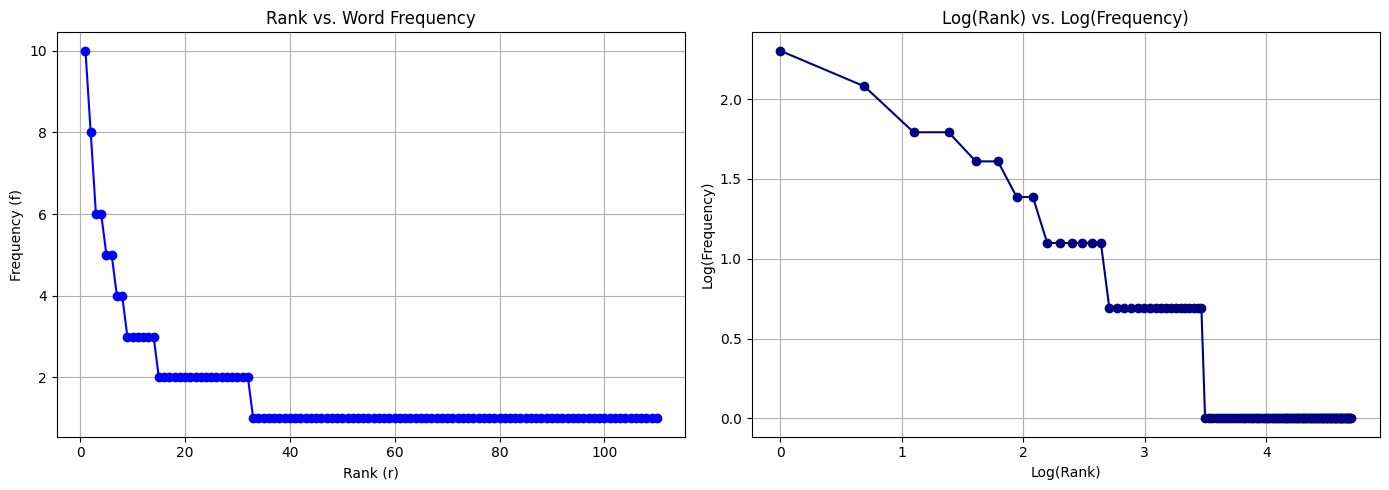

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Rank vs. Frequency
ax1.plot(ranks, frequencies, marker="o", color="blue", linewidth=1.5)
ax1.set_title("Rank vs. Word Frequency")
ax1.set_xlabel("Rank (r)")
ax1.set_ylabel("Frequency (f)")
ax1.grid(True)

# Graph 2: Log(Rank) vs. Log(Frequency)
ax2.plot(
    np.log(ranks), np.log(frequencies), marker="o", color="navy", linewidth=1.5
)
ax2.set_title("Log(Rank) vs. Log(Frequency)")
ax2.set_xlabel("Log(Rank)")
ax2.set_ylabel("Log(Frequency)")
ax2.grid(True)

plt.tight_layout()
plt.show()

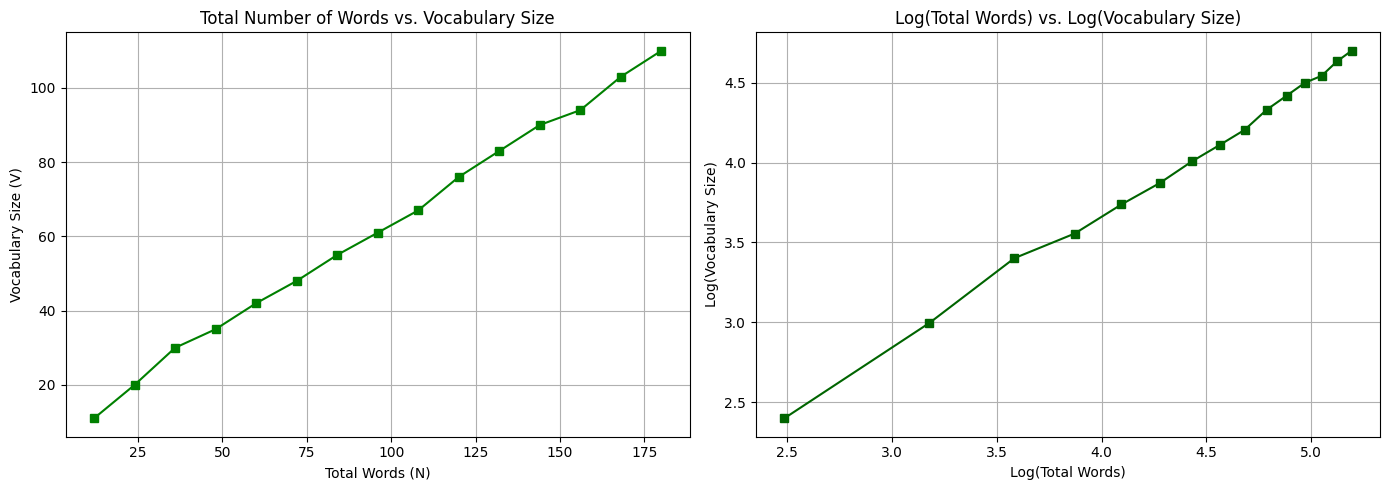

In [6]:
fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(14, 5))

# Graph 3: Total Words vs. Vocabulary Size
ax3.plot(
    total_tokens_steps, vocab_sizes, marker="s", color="green", linewidth=1.5
)
ax3.set_title("Total Number of Words vs. Vocabulary Size")
ax3.set_xlabel("Total Words (N)")
ax3.set_ylabel("Vocabulary Size (V)")
ax3.grid(True)

# Graph 4: Log(Total Words) vs. Log(Vocabulary Size)
ax4.plot(
    np.log(total_tokens_steps),
    np.log(vocab_sizes),
    marker="s",
    color="darkgreen",
    linewidth=1.5,
)
ax4.set_title("Log(Total Words) vs. Log(Vocabulary Size)")
ax4.set_xlabel("Log(Total Words)")
ax4.set_ylabel("Log(Vocabulary Size)")
ax4.grid(True)

plt.tight_layout()
plt.show()